# Chapter 29 | Worked solutions

*Scientific Sequences and Biological Structure*

All eleven exercises distinguish sequence order, learned representations,
geometric contacts and structural confidence. Exercises 1-4 use hand calculations,
5-8 use the canonical NumPy helpers, and 9-11 design scientific evaluations.
The written PDF contains every explanation and three plots; the notebook and
its PDF add code and recorded checks. Supplied vectors and confidence values
are teaching fixtures, not outputs from a protein model.

Open this notebook inside `transformers-book` with the repository requirements
and Matplotlib installed. Restart the kernel and run every cell in order.
The examples run on CPU without downloading models or biological datasets.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch29_protein"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
from examples.ch29_protein.model import (
    AMINO_ACIDS, residue_composition, dipeptide_frequencies,
    mean_pool_residues, contact_map,
)
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "figure.dpi": 120})
np.set_printoptions(precision=4, suppress=True)

## 1. Read aligned columns

Read positions 2 and 4 from each row of the alignment, using one-based indices.
They are target-alignment positions, not arbitrary adjacent letters.

| Row | Sequence | Letters at columns 2 and 4 |
|---:|---|---|
| 1 | ACDG | C, G |
| 2 | ACEG | C, G |
| 3 | ASDA | S, A |
| 4 | ASEA | S, A |

The counts are CG: 2 and SA: 2; CA and SG occur zero times. One explanation
is shared ancestry: rows 1 and 2 inherited CG from one branch, while rows 3
and 4 inherited SA from another. This association need not imply a physical
contact. Four related rows are not four independent experiments.

In the chapter's toy example, four rows and four positions happen to give
two axes of length four. The pair grid still indexes two target positions,
not two sequences. A learned pair vector can be directed and need not be a
symmetric distance or a contact probability.

In [3]:
from collections import Counter

alignment = ["ACDG", "ACEG", "ASDA", "ASEA"]
column_pairs = Counter(row[1]+row[3] for row in alignment)
assert column_pairs == {"CG": 2, "SA": 2}
print("Columns 2 and 4:", dict(column_pairs))
for length in [512, 1024]:
    bytes_per_pair_array = length**2 * 64 * 4
    print(f"Illustrative L={length}, width=64, float32: "
          f"{bytes_per_pair_array / 2**20:.0f} MiB for one pair array")
assert (1024**2)/(512**2) == 4

Columns 2 and 4: {'CG': 2, 'SA': 2}
Illustrative L=512, width=64, float32: 64 MiB for one pair array
Illustrative L=1024, width=64, float32: 256 MiB for one pair array


## 2. Preserve some order

Both CAAC and CCAA contain two A and two C residues. Divide counts by length
four to get A = C = 1/2; all other composition entries are zero.
Slide a two-residue window by one position, giving three overlapping pairs.

| Sequence | Adjacent pairs in order | Nonzero normalized counts |
|---|---|---|
| CAAC | CA, AA, AC | CA = AA = AC = 1/3 |
| CCAA | CC, CA, AA | CC = CA = AA = 1/3 |

CA and AC occupy different matrix entries: the first letter sets the row and
the second sets the column. The pair frequencies distinguish these sequences,
although Exercise 5 will show that they do not retain every aspect of order.

In [4]:
for sequence, expected in [
    ("CAAC", {"CA": 1, "AA": 1, "AC": 1}),
    ("CCAA", {"CC": 1, "CA": 1, "AA": 1}),
]:
    counts = Counter(sequence[i:i+2] for i in range(len(sequence)-1))
    assert counts == expected
    assert sequence.count("A")/len(sequence) == .5
    assert sequence.count("C")/len(sequence) == .5
    print(sequence, {pair: count/(len(sequence)-1) for pair, count in counts.items()})

CAAC {'CA': 0.3333333333333333, 'AA': 0.3333333333333333, 'AC': 0.3333333333333333}
CCAA {'CC': 0.3333333333333333, 'CA': 0.3333333333333333, 'AA': 0.3333333333333333}


## 3. Pool only residues

The mask $(0,1,1,0)$ keeps the vectors $(2,0)$ and $(0,4)$.
Their coordinate-wise mean is

$$
\frac{(2,0)+(0,4)}{2}=(1,2).
$$

If all four positions are included, the two marker vectors cancel in the sum,
but they still count in the denominator:

$$
\frac{(10,10)+(2,0)+(0,4)+(-10,-10)}{4}=(0.5,1).
$$

Masking therefore matters even when the unwanted vectors happen to sum to zero.
At least one residue must be selected. The helper selects rows before averaging;
the numerator and denominator both depend only on actual residues.

In [5]:
four_vectors = np.array([[10, 10], [2, 0], [0, 4], [-10, -10]])
selected_mean = mean_pool_residues(four_vectors, [False, True, True, False])
all_mean = four_vectors.mean(axis=0)
np.testing.assert_array_equal(selected_mean, [1, 2])
np.testing.assert_array_equal(all_mean, [.5, 1])
print("Residues only:", selected_mean)
print("All four positions:", all_mean)

Residues only: [1. 2.]
All four positions: [0.5 1. ]


## 4. Read a geometric threshold

The three residues are numbered in the given chain order. A pair must pass
both the distance cutoff and the sequence-separation rule.

| Unordered pair | Index separation | Distance | Accepted? |
|---|---:|---|---|
| $(1,2)$ | 1 | 2 | No: adjacent in sequence. |
| $(1,3)$ | 2 | 3 | Yes: both tests include equality. |
| $(2,3)$ | 1 | $\sqrt{13}>3$ | No: fails both tests. |

Only $(1,3)$ is accepted. It activates matrix entries $(1,3)$ and $(3,1)$,
which are array entries `[0,2]` and `[2,0]` in zero-based Python indexing.
Every other Boolean entry is false. In the book's diagram convention, pairs
excluded by sequence separation would be displayed as dashes. A Boolean
false alone does not say which cutoff failed.

In [6]:
three_points = np.array([[0, 0, 0], [2, 0, 0], [0, 3, 0]])
three_map = contact_map(three_points, 3, 2)
expected = np.array([[0, 0, 1], [0, 0, 0], [1, 0, 0]], dtype=bool)
np.testing.assert_array_equal(three_map, expected)
assert three_map.sum() == 2
assert np.triu(three_map, 1).sum() == 1
print(three_map.astype(int))
print("One-based unique pair:", (np.argwhere(np.triu(three_map, 1))+1).tolist())

[[0 0 1]
 [0 0 0]
 [1 0 0]]
One-based unique pair: [[1, 3]]


## 5. Verify the pair representation

A composition vector gives the fraction of residues that are each
letter. In both `CAAC` and `CCAA`, two of the four residues are A and
two are C. The A and C entries are each $2/4 = 1/2$. Every other entry
is zero.

A dipeptide is a pair of neighboring residues read in sequence order.
Move a two-residue window one position at a time. In `CAAC` it gives
`CA`, `AA`, and `AC`. In `CCAA` it gives `CC`, `CA`, and `AA`. The
pair matrix stores each frequency at the row for the first letter and
the column for the second. Each listed pair occurs once among the three
windows, so it has frequency $1/3$. All other pair entries are zero.

The expected arrays below come from those counts. The checks compare
every entry, including the zeros, and verify that both totals are one
for each four-residue sequence.

In [7]:
from examples.ch29_protein.model import (
    AMINO_ACIDS,
    dipeptide_frequencies,
    residue_composition,
)

alphabet_size = len(AMINO_ACIDS)
a_index = AMINO_ACIDS.index("A")
c_index = AMINO_ACIDS.index("C")
expected_composition = np.zeros(alphabet_size)
expected_composition[[a_index, c_index]] = 1 / 2

pairs_by_sequence = {
    "CAAC": ("CA", "AA", "AC"),
    "CCAA": ("CC", "CA", "AA"),
}
for sequence, pairs in pairs_by_sequence.items():
    composition = residue_composition(sequence)
    frequencies = dipeptide_frequencies(sequence)

    expected_frequencies = np.zeros((alphabet_size, alphabet_size))
    for first, second in pairs:
        row = AMINO_ACIDS.index(first)
        column = AMINO_ACIDS.index(second)
        expected_frequencies[row, column] = 1 / 3

    np.testing.assert_allclose(composition, expected_composition)
    np.testing.assert_allclose(frequencies, expected_frequencies)
    np.testing.assert_allclose(composition.sum(), 1)
    np.testing.assert_allclose(frequencies.sum(), 1)

    print(f"{sequence}")
    print(f"  A={composition[a_index]:g}, C={composition[c_index]:g}")
    for first, second in ("AA", "AC", "CA", "CC"):
        row = AMINO_ACIDS.index(first)
        column = AMINO_ACIDS.index(second)
        print(f"  {first}{second}={frequencies[row, column]:.6f}")
    print(f"  Composition total = {composition.sum():g}")
    print(f"  Dipeptide total   = {frequencies.sum():g}")

CAAC
  A=0.5, C=0.5
  AA=0.333333
  AC=0.333333
  CA=0.333333
  CC=0.000000
  Composition total = 1
  Dipeptide total   = 1
CCAA
  A=0.5, C=0.5
  AA=0.333333
  AC=0.000000
  CA=0.333333
  CC=0.333333
  Composition total = 1
  Dipeptide total   = 1


The sequence `A` contains one residue, so its composition assigns all
the frequency to A. Its composition total is still one. It contains
zero adjacent pairs, so there is no positive pair count to divide by.
The function returns a matrix of zeros in this case, with total zero.

In [8]:
composition = residue_composition("A")
frequencies = dipeptide_frequencies("A")

expected_composition = np.zeros(alphabet_size)
expected_composition[a_index] = 1
np.testing.assert_array_equal(composition, expected_composition)
np.testing.assert_array_equal(
    frequencies, np.zeros((alphabet_size, alphabet_size))
)
np.testing.assert_allclose(composition.sum(), 1)
np.testing.assert_allclose(frequencies.sum(), 0)

print(f"A composition entry = {composition[a_index]:g}")
print(f"Composition total   = {composition.sum():g}")
print(f"Dipeptide total     = {frequencies.sum():g}")

A composition entry = 1
Composition total   = 1
Dipeptide total     = 0


For AACAC, the windows are AA, AC, CA, AC. For ACAAC they are AC,
CA, AA, AC. Both therefore have AA = 1/4, AC = 1/2 and CA = 1/4, with all
other pair frequencies zero. Both have A = 3/5 and C = 2/5.
The order differs but both summaries agree. Dipeptides retain more order than
composition, yet they cannot always reconstruct the original sequence.
The heatmap shows only the A/C and AA/AC/CA/CC entries; all others are zero.

AACAC and ACAAC pair frequencies agree: True


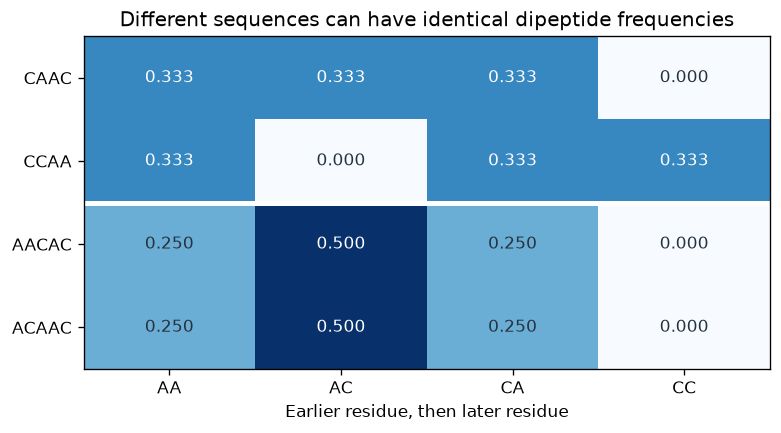

In [9]:
sequences = ["CAAC", "CCAA", "AACAC", "ACAAC"]
pair_names = ["AA", "AC", "CA", "CC"]
small_pairs = np.array([
    [dipeptide_frequencies(s)[AMINO_ACIDS.index(p[0]), AMINO_ACIDS.index(p[1])]
     for p in pair_names] for s in sequences
])
np.testing.assert_allclose(small_pairs[2:], [[.25, .5, .25, 0]]*2)
np.testing.assert_array_equal(residue_composition(sequences[2]),
                              residue_composition(sequences[3]))
fig, ax = plt.subplots(figsize=(6.4, 3.5), layout="constrained")
ax.imshow(small_pairs, vmin=0, vmax=.5, cmap="Blues", aspect="auto")
ax.set_xticks(range(4), pair_names)
ax.set_yticks(range(4), sequences)
ax.set(xlabel="Earlier residue, then later residue",
       title="Different sequences can have identical dipeptide frequencies")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{small_pairs[i,j]:.3f}", ha="center", va="center",
                color="white" if small_pairs[i,j] >= 1/3 else "#26323D")
ax.axhline(1.5, color="white", linewidth=3)
display(fig)
plt.close(fig)
print("AACAC and ACAAC pair frequencies agree:", np.array_equal(small_pairs[2], small_pairs[3]))

## 6. Change only padding

The chapter's pooling figure shows five vectors in token order. The
beginning marker (BOS) has $(9,9)$, residue A has $(1,0)$, residue C has
$(1,2)$, the ending marker (EOS) has $(-9,-9)$, and padding (PAD) has
$(0,0)$. The mask has one Boolean value per row. Only the two residue
rows have a value of `True`.

Mean pooling averages each coordinate over the selected rows.

$$
\frac{(1,0)+(1,2)}{2}=(1,1).
$$

Copy the array, replace the last row with $(7,9)$, and pass the same
mask both times. The two selected rows and their count stay the same.
Both runs should therefore return $(1,1)$.

In [10]:
from examples.ch29_protein.model import mean_pool_residues

embeddings = np.array([
    [9, 9],    # BOS
    [1, 0],    # A
    [1, 2],    # C
    [-9, -9],  # EOS
    [0, 0],    # PAD
])
residue_mask = np.array([False, True, True, False, False])

pooled = mean_pool_residues(embeddings, residue_mask)
changed_embeddings = embeddings.copy()
changed_embeddings[-1] = [7, 9]
pooled_after = mean_pool_residues(changed_embeddings, residue_mask)

np.testing.assert_array_equal(pooled, [1, 1])
np.testing.assert_array_equal(pooled_after, pooled)

print(f"Pooled with padding (0, 0) = {pooled}")
print(f"Pooled with padding (7, 9) = {pooled_after}")

Pooled with padding (0, 0) = [1. 1.]
Pooled with padding (7, 9) = [1. 1.]


Both calls return the same two coordinates. The function selects rows
using the mask before taking the mean. The padding vector contributes
neither to the coordinate sums nor to the number of rows averaged.

This check holds the supplied residue vectors fixed. When using a real
encoder, padding must also be handled by its attention mask. Excluding padding
from the final mean cannot repair residue vectors that already read padding
incorrectly. Freeze the encoder's weights and use evaluation mode for reproducible
features; those two settings have different purposes.

## 7. Translate the coordinates

Use the four points from the chapter's contact-map figure.
In chain order they are $(0,0,0)$, $(3,0,0)$, $(0,4,0)$, and
$(8,0,0)$. A pair is a contact when its Euclidean distance is at
most 5 and its residue numbers differ by at least 2.

Using one-based residue numbers, only three unordered pairs
pass the sequence-separation rule.

| Pair | Index separation | Distance | Contact |
| --- | ---: | ---: | --- |
| $(1,3)$ | 2 | 4 | Yes |
| $(1,4)$ | 3 | 8 | No |
| $(2,4)$ | 2 | 5 | Yes |

For each of these pairs, just one coordinate differs, so the
distance is the size of that difference. Pair $(2,4)$ qualifies
at both cutoffs. Pair $(1,2)$ is only 3 units apart, but its index
separation is 1, so its entry is false. The diagonal has
separation 0. Each accepted pair contributes two true entries,
one in each half of the symmetric matrix.

In [11]:
from examples.ch29_protein.model import contact_map

coordinates = np.array(
    [[0, 0, 0], [3, 0, 0], [0, 4, 0], [8, 0, 0]]
)
threshold = 5
separation = 2
original_map = contact_map(coordinates, threshold, separation)

expected_map = np.array(
    [[0, 0, 1, 0],
     [0, 0, 0, 1],
     [1, 0, 0, 0],
     [0, 1, 0, 0]],
    dtype=bool,
)
np.testing.assert_array_equal(original_map, expected_map)
print("Original map (1 = contact)")
print(original_map.astype(int))

Original map (1 = contact)
[[0 0 1 0]
 [0 0 0 1]
 [1 0 0 0]
 [0 1 0 0]]


A translation adds the same vector to every point. If
$\mathbf{p}_i$ is the coordinate of residue $i$ and
$\mathbf{t}=(10,-3,2)$, then
$$
(\mathbf{p}_i+\mathbf{t})-(\mathbf{p}_j+\mathbf{t})
= \mathbf{p}_i-\mathbf{p}_j.
$$
Taking the length of that difference gives the same distance
as before. The chain order stays fixed, so the index separation
also stays fixed. Since each entry depends only on these two
quantities, a shared translation preserves the whole map.

In [12]:
translation = np.array([10, -3, 2])
shifted_coordinates = coordinates + translation
shifted_map = contact_map(shifted_coordinates, threshold, separation)

np.testing.assert_array_equal(shifted_map, original_map)
print("Translated map (1 = contact)")
print(shifted_map.astype(int))

Translated map (1 = contact)
[[0 0 1 0]
 [0 0 0 1]
 [1 0 0 0]
 [0 1 0 0]]


The rotation $(x,y,z)\mapsto(-y,x,z)$ also preserves distances and
sequence indices. It changes coordinates while leaving the contact map invariant.
The array multiplication below applies that rotation to row vectors.

Moving the threshold to the next representable floating-point number below 5
removes pair $(2,4)$, whose distance is exactly 5. Pair $(1,3)$ at distance 4
remains. The code's inclusive comparison is intentional. Large translations or
values extremely close to a cutoff can introduce rounding effects; mathematical
invariance does not imply exact floating-point equality under every transformation.

The three displayed maps use the same coordinate-index convention. Their row
numbers are consecutive positions of one chain. Missing residues or concatenated
chains would require explicit sequence indices and chain-aware rules.

Threshold below 5: np.float64(4.999999999999999)
Remaining one-based pair: [[1, 3]]


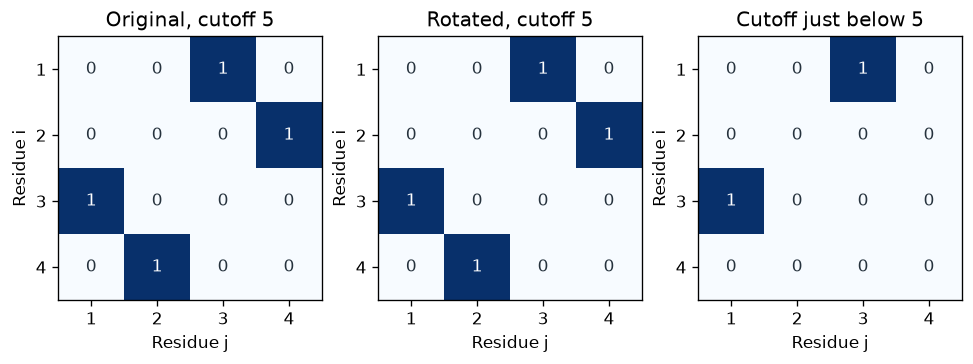

In [13]:
rotation = np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1]])
rotated = coordinates @ rotation.T
rotated_map = contact_map(rotated, threshold, separation)
np.testing.assert_array_equal(rotated_map, original_map)
lower_threshold = np.nextafter(5.0, 0)
lower_map = contact_map(coordinates, lower_threshold, separation)
assert np.triu(lower_map, 1).sum() == 1
assert lower_map[0, 2] and not lower_map[1, 3]
fig, axes = plt.subplots(1, 3, figsize=(8, 3), layout="constrained")
for ax, matrix, title in zip(axes, [original_map, rotated_map, lower_map],
                             ["Original, cutoff 5", "Rotated, cutoff 5", "Cutoff just below 5"]):
    ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(4), range(1, 5))
    ax.set_yticks(range(4), range(1, 5))
    ax.set(xlabel="Residue j", ylabel="Residue i", title=title)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, int(matrix[i,j]), ha="center", va="center",
                    color="white" if matrix[i,j] else "#26323D")
display(fig)
plt.close(fig)
print("Threshold below 5:", repr(lower_threshold))
print("Remaining one-based pair:", (np.argwhere(np.triu(lower_map, 1))+1).tolist())

## 8. Measure two classes

The first two proteins are correctly predicted as A. The
third is an A predicted as B, and the fourth is the only
true B. We score each class separately. For the class being
scored, a true positive ($TP$) has that true label and is
predicted to have it. A false positive ($FP$) receives that
prediction in error. A false negative ($FN$) has that true label
but is predicted to belong to the other class.

For each class, compute $F_1 = 2TP/(2TP + FP + FN)$. Both classes
have a positive denominator in both runs. The support is the
number of proteins with that true label, which equals $TP+FN$.
Macro-F1 is the mean of the two class scores, giving A and B
equal weight even though A has three examples and B has one.

In [14]:
true_labels = np.array(["A", "A", "A", "B"])
original_predictions = np.array(["A", "A", "B", "B"])
changed_predictions = original_predictions.copy()
changed_predictions[-1] = "A"
classes = ("A", "B")


def class_scores(true_labels, predictions, label):
    has_label = true_labels == label
    predicted_label = predictions == label
    tp = int(np.count_nonzero(has_label & predicted_label))
    fp = int(np.count_nonzero(~has_label & predicted_label))
    fn = int(np.count_nonzero(has_label & ~predicted_label))
    f1 = 2 * tp / (2 * tp + fp + fn)
    return tp, fp, fn, f1

Before the change, protein 3 contributes a false negative for
A and a false positive for B. This gives A an F1 of $4/5$ and B
an F1 of $2/3$, for a macro-F1 of $11/15$.

After the change, protein 4 also becomes an error. It contributes
a false positive for A and a false negative for B. A keeps its
two true positives and now scores $4/6=2/3$. B loses its only
true positive and scores 0. The new macro-F1 is $1/3$.

In [15]:
comparisons = [
    ("Original predictions", original_predictions),
    ("Changed final prediction", changed_predictions),
]
expected_counts = [[(2, 0, 1), (1, 1, 0)], [(2, 1, 1), (0, 1, 1)]]
expected_f1 = [[4 / 5, 2 / 3], [2 / 3, 0]]
expected_macro = [11 / 15, 1 / 3]

for index, (title, predictions) in enumerate(comparisons):
    print(title)
    print("Class  Support  TP  FP  FN      F1")
    scores = []
    for label, counts in zip(classes, expected_counts[index]):
        tp, fp, fn, f1 = class_scores(true_labels, predictions, label)
        assert (tp, fp, fn) == counts
        scores.append(f1)
        print(f"{label:<5} {tp + fn:>7} {tp:>3} {fp:>3} {fn:>3}"
              f" {f1:>7.4f}")

    macro_f1 = float(np.mean(scores))
    np.testing.assert_allclose(scores, expected_f1[index])
    np.testing.assert_allclose(macro_f1, expected_macro[index])
    print(f"Macro-F1 = {macro_f1:.4f}\n")

Original predictions
Class  Support  TP  FP  FN      F1
A           3   2   0   1  0.8000
B           1   1   1   0  0.6667
Macro-F1 = 0.7333

Changed final prediction
Class  Support  TP  FP  FN      F1
A           3   2   1   1  0.6667
B           1   0   1   1  0.0000
Macro-F1 = 0.3333



## 9. Split by relatedness

Suppose 40 proteins labeled nuclear all belong to one family. A random
protein split can put near relatives on both sides and reward recognition of
that family's patterns. To test transfer across families, assign entire
families to training, validation or test. A target allocation such as 70/15/15
percent is subordinate to having enough distinct families for the classes being
evaluated. Families can contain several labels, so inspect actual sequence
and family counts per class after assignment.

Fit preprocessing and classifiers on training families, select settings on
validation families and score the test once. Record the source and version of
family annotations. Screen duplicates and close relatives that have different
family labels. If nominal groups are linked by near matches under the declared
identity and alignment-coverage rule, keep them together or omit problematic
records under a rule fixed before scoring. Check the closest cross-split
pairs; distinct group names alone do not certify a sequence-identity bound.

A label represented by only one family cannot have supervised training
examples and a family-disjoint transfer test at the same time. One defensible
choice keeps that family entirely in training and marks its test recall/F1
unavailable for this transfer question. Predefine a macro average over the
classes with held-out reference support, list them, and report every class's
support. Predictions of the unsupported label on other test classes still
count as mistakes for those examples. This restricted macro is not an estimate
of transfer for all labels. More independent families are needed for the
single-family label.

The illustrative assignment below uses N and C families for supported labels,
and a single M family retained in training. It verifies bookkeeping only;
real sequence comparisons are still needed to audit relatedness.

In [16]:
families = {f"{label}{i}": {"label": label, "count": 2}
            for label in ["N", "C"] for i in range(1, 5)}
families["M1"] = {"label": "M", "count": 4}
split_families = {
    "train": {"N1", "N2", "C1", "C2", "M1"},
    "validation": {"N3", "C3"}, "test": {"N4", "C4"},
}
names = list(split_families)
assert set.union(*split_families.values()) == set(families)
assert all(split_families[a].isdisjoint(split_families[b])
           for i, a in enumerate(names) for b in names[:i])
for split, group in split_families.items():
    support = {label: sum(families[f]["count"] for f in group
                          if families[f]["label"] == label) for label in ["N", "C", "M"]}
    print(split, "families:", len(group), "sequence support:", support)
assert "M1" in split_families["train"]
scored_test_classes = ("N", "C")
print("Prespecified supported-class macro:", scored_test_classes)

train families: 5 sequence support: {'N': 4, 'C': 4, 'M': 4}
validation families: 2 sequence support: {'N': 2, 'C': 2, 'M': 0}
test families: 2 sequence support: {'N': 2, 'C': 2, 'M': 0}
Prespecified supported-class macro: ('N', 'C')


## 10. Test what an embedding adds

Use the same family-disjoint labeled splits and the same eligible test proteins
for composition, dipeptides and frozen embeddings. Decide how to handle duplicate
sequences, ambiguous symbols, incomplete chains and long sequences in advance.
If the encoder's limit excludes some proteins, define a common eligible population
and report exclusions. Quietly dropping difficult examples only for one method
changes the comparison.

Composition has 20 entries; dipeptides have 400 after flattening, with the
chapter's all-zero convention for a single residue. For embeddings, record the
checkpoint, layer, feature width, residue mask, attention mask, evaluation mode
and pooling rule. Mean contextual vectors can preserve order information that a
mean of static letter vectors loses. Keep encoder weights frozen.

Fit the same classifier family, such as regularized multinomial logistic
regression, for each representation. Learn any scaling on training proteins,
tune regularization on the same validation set with equal search budgets, and
report per-class scores, support and macro-F1 on identical test proteins.
Different feature widths and prior training remain part of what is being compared.

Record the encoder's pretraining corpus/version and cutoff when documented.
If searchable, audit identifiers, exact sequence hashes and close matches with
an explicit alignment method and identity/coverage rule. Report exact matches,
nonexact close matches, no match detected in the searched corpus, and unchecked
cases separately. An unavailable corpus means overlap is unknown, not absent.
A family split in the labeled task cannot establish pretraining independence.

Fit a length-only classifier using log length on the same splits. Define bins
from training lengths, then compare representations on the same test proteins
within each bin, reporting sample and class counts and a common supported-class
set. Also give every representation the same length feature and repeat. An
embedding advantage that persists within length strata and after this control
supports a claim beyond length alone; it does not prove that all confounding
factors have been removed.

The fixture checks a common length-eligibility rule and training-defined bins.
It does not run a pretrained encoder or invent benchmark scores.

In [17]:
training_lengths = np.array([30, 60, 100, 180])
test_lengths = np.array([40, 70, 120, 240])
maximum_residues = 200  # Supplied teaching limit, not an ESM checkpoint claim.
eligible = test_lengths <= maximum_residues
boundary = np.median(training_lengths)
assert boundary == 80
assert eligible.tolist() == [True, True, True, False]
bins = np.where(test_lengths[eligible] <= boundary, "short", "long")
assert bins.tolist() == ["short", "short", "long"]
print("Training-derived boundary:", boundary)
print("Shared eligible test lengths:", test_lengths[eligible])
print("Shared test bins:", bins)
print("Excluded test lengths:", test_lengths[~eligible])
print("Length-only input for eligible cases:", np.log(test_lengths[eligible]))
print("Representation widths: composition 20; dipeptides 400; encoder recorded separately.")

Training-derived boundary: 80.0
Shared eligible test lengths: [ 40  70 120]
Shared test bins: ['short' 'short' 'long']
Excluded test lengths: [240]
Length-only input for eligible cases: [3.6889 4.2485 4.7875]
Representation widths: composition 20; dipeptides 400; encoder recorded separately.


## 11. Assess a structural claim

One domain may supply a pocket wall and the other a putative ligand contact.
Changing the angle between them can destroy the proposed pocket while preserving
each domain's local geometry. Inspect pLDDT at the candidate residues and the
linker, then inspect PAE within each domain and in both directions across domains.

In the constructed six-position plot, domain A is 1-3 and domain B is 4-6.
The supplied pLDDT values are all 94-97. Off-diagonal PAE values within each
domain are 2 angstroms; the two cross-domain blocks are 18 and 12 angstroms.
Here the row is the residue whose positional error is estimated and the column
is the alignment anchor. Thus PAE[1,4] is 18 and PAE[4,1] is 12 with one-based
indices. The direction changes the question; PAE need not be symmetric.

These values support greater confidence in each local domain than in their
relative placement. They do not say that the domains are 18 or 12 angstroms
apart: PAE is predicted aligned error, not distance. Nor are they measured
errors against a known structure. pLDDT is not a probability of binding or
function. The entire plot is a supplied teaching construction.

Separate two experimental questions. A direct binding measurement, such as
isothermal titration calorimetry, can test whether the ligand interacts with
the full-length protein under the assay conditions. Include background controls
and replication. Locating the interaction requires complementary evidence,
such as a ligand-bound experimental structure with adequate support for the
ligand and nearby residues in both domains.

Candidate-contact changes on each side, compared with the unmodified protein
and a control change away from the site, can test the proposed explanation.
Check folding and assembly: reduced binding can arise from a disrupted protein
or altered domain orientation rather than loss of a direct contact. Binding
measurements, structural evidence and these controls address different parts
of the claim. A confident predicted pocket alone does not establish it.

Teaching PAE(1,4) / PAE(4,1): 18.0 12.0
High local confidence does not validate a cross-domain binding site.


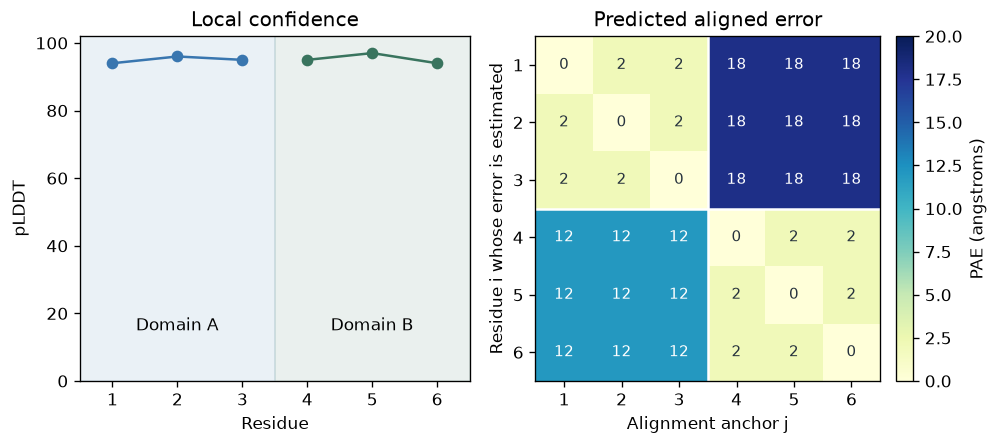

In [18]:
plddt = np.array([94, 96, 95, 95, 97, 94])
pae = np.full((6, 6), 2.0)
pae[:3, 3:] = 18
pae[3:, :3] = 12
np.fill_diagonal(pae, 0)
assert (pae[0, 3], pae[3, 0]) == (18, 12)
assert not np.array_equal(pae, pae.T)
fig, (ax, bx) = plt.subplots(1, 2, figsize=(8.2, 3.6), layout="constrained")
ax.axvspan(.5, 3.5, color="#3976AF", alpha=.1)
ax.axvspan(3.5, 6.5, color="#39745E", alpha=.1)
ax.plot(range(1, 4), plddt[:3], "o-", color="#3976AF")
ax.plot(range(4, 7), plddt[3:], "o-", color="#39745E")
ax.text(2, 15, "Domain A", ha="center")
ax.text(5, 15, "Domain B", ha="center")
ax.set(xlim=(.5, 6.5), ylim=(0, 102), xticks=range(1, 7),
       xlabel="Residue", ylabel="pLDDT", title="Local confidence")
im = bx.imshow(pae, vmin=0, vmax=20, cmap="YlGnBu")
bx.axhline(2.5, color="white"); bx.axvline(2.5, color="white")
bx.set_xticks(range(6), range(1, 7)); bx.set_yticks(range(6), range(1, 7))
bx.set(xlabel="Alignment anchor j", ylabel="Residue i whose error is estimated",
       title="Predicted aligned error")
for i in range(6):
    for j in range(6):
        bx.text(j, i, f"{pae[i,j]:g}", ha="center", va="center",
                color="white" if pae[i,j] >= 12 else "#26323D", fontsize=9)
fig.colorbar(im, ax=bx, label="PAE (angstroms)", fraction=.046, pad=.04)
display(fig)
plt.close(fig)
print("Teaching PAE(1,4) / PAE(4,1):", pae[0,3], pae[3,0])
print("High local confidence does not validate a cross-domain binding site.")